In [80]:
# Import libraries needed
import numpy as np
import pandas as pd

# For graph plot
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Tests
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.stattools import coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen 
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [54]:
# Import data and settings
df = pd.read_csv("data.csv")

mete_col = ["Diurnal temperature range (°C)", "Mean temperature (°C)", "Mean humidity (%)", "Solar radiation (MJ/m²)", "Air pressure (hPa)", "Dew point temperature (°C)", "Wind speed (km/h)", "Mean UV"]
flu_col = ["H1", "H3", "B", "AandB"]
control_col = ["Week", "ContainmentHealthIndex_Average", "pandemic_flag"]

In [55]:
# Quick overview of the data
df.head()

,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag
0,2002,36,2002-09-01,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,1,12,3.0,19,0.0,0.0
1,2002,37,2002-09-08,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,0,6,4.0,15,0.0,0.0
2,2002,38,2002-09-15,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,0,4,4.0,13,0.0,0.0
3,2002,39,2002-09-22,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,0,2,6.0,10,0.0,0.0
4,2002,40,2002-09-29,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,0,6,2.0,8,0.0,0.0


In [56]:
# Infromation of the DataFrmae
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1253 entries, 0 to 1252
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            1253 non-null   int64  
 1   Week                            1253 non-null   int64  
 2   From                            1253 non-null   object 
 3   Diurnal temperature range (°C)  1253 non-null   float64
 4   Mean temperature (°C)           1253 non-null   float64
 5   Mean humidity (%)               1253 non-null   float64
 6   Solar radiation (MJ/m²)         1253 non-null   float64
 7   Air pressure (hPa)              1253 non-null   float64
 8   Dew point temperature (°C)      1253 non-null   float64
 9   Wind speed (km/h)               1253 non-null   float64
 10  Mean UV                         1253 non-null   float64
 11  H1                              1253 non-null   int64  
 12  H3                              12

In [57]:
# Statistical information for the meteorological data
df[mete_col].describe()

,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
count,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,14.864006,23.383599,78.736233,13.996983,1012.860774,19.225339,10.074062,2.891700
std,3.539967,5.005770,8.494599,5.270534,6.067874,5.963239,1.811932,1.256406
min,3.900000,8.900000,43.000000,2.020000,996.750000,-0.100000,5.550000,0.400000
25%,12.200000,19.100000,74.500000,9.930000,1008.000000,14.900000,8.800000,2.000000
50%,14.000000,24.400000,80.000000,14.240000,1012.800000,20.500000,10.000000,3.000000
75%,17.000000,28.000000,85.000000,17.680000,1017.650000,24.800000,11.200000,4.000000
max,27.700000,31.700000,94.000000,26.460000,1027.700000,26.800000,17.800000,7.000000


In [58]:
# Statistical information for the influenza data
df[flu_col].describe()

,H1,H3,B,AandB
count,1253.000000,1253.000000,1252.000000,1253.000000
mean,69.613727,115.727055,44.593450,261.437350
std,189.083854,233.728958,131.615377,439.621172
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,5.000000,3.000000,27.000000
50%,4.000000,28.000000,12.500000,103.000000
75%,47.000000,125.000000,41.000000,305.000000
max,1999.000000,2560.000000,1978.000000,4679.000000


In [ ]:
# Statistical information for the control variables 
df[control_col].describe()

,Week,ContainmentHealthIndex_Average,pandemic_flag
count,1253.000000,1253.000000,1253.000000
mean,26.605746,8.128132,0.131684
std,15.077257,21.983305,0.338282
min,1.000000,0.000000,0.000000
25%,14.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000
75%,40.000000,0.000000,0.000000
max,53.000000,82.140000,1.000000


Note that the table above shows a high difference between the mean and standard deviation. 
For all influenza types, the lower quartile (25%) is equal to or close to 0, which means that the data is highly zero inflated.

In [60]:
# Check missing values in each columns
print(f"Number of NA values in each rows: \n{df.isna().sum()}")

Number of NA values in each rows: 
Year                              0
Week                              0
From                              0
Diurnal temperature range (°C)    0
Mean temperature (°C)             0
Mean humidity (%)                 0
Solar radiation (MJ/m²)           0
Air pressure (hPa)                0
Dew point temperature (°C)        0
Wind speed (km/h)                 0
Mean UV                           0
H1                                0
H3                                0
B                                 1
AandB                             0
ContainmentHealthIndex_Average    0
pandemic_flag                     0
dtype: int64


In [61]:
# Check how many 0 exists in the target variables
(df[flu_col]==0).sum()

H1       472
H3       133
B        137
AandB     76
dtype: int64

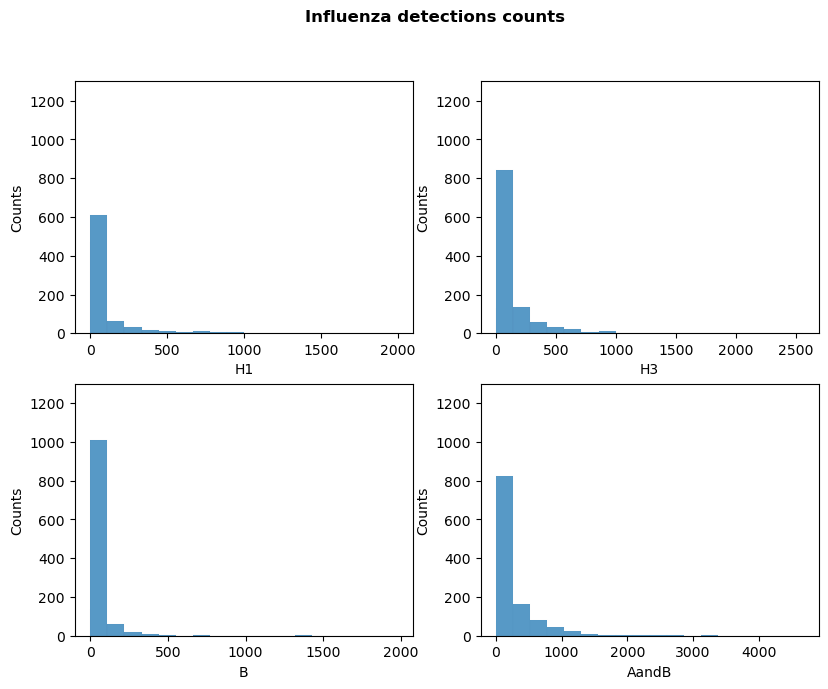

In [62]:
# Visualize the ratio of counts
fig, axes = plt.subplots(2, 2, figsize=(6.4*1.5, 4.8*1.5))

for i, col in enumerate(flu_col):
    remaining = np.linspace(1, df[col].max(), 19)
    custom_bins = np.insert(remaining, 0, 0)
    
    sns.histplot(x=col, data=df, ax=axes[i//2, i%2], bins=custom_bins)
    axes[i//2, i%2].set_xlabel(col)
    axes[i//2, i%2].set_ylabel("Counts")
    axes[i//2, i%2].set_ylim(0, 1300)
    
plt.suptitle("Influenza detections counts", fontweight="bold")
plt.show()

We can see that the influenza data are inflated by zero

Find the correlation between the meterological data and influenza count, then visualize it using a heatmap

,H1,H3,B,AandB
Diurnal temperature range (°C),-0.021623,-0.112394,0.042635,-0.046062
Mean temperature (°C),0.005841,0.098653,-0.122834,-0.026245
Mean humidity (%),0.106987,0.128419,0.128242,0.161329
Solar radiation (MJ/m²),-0.032933,-0.001178,-0.108846,-0.074390
Air pressure (hPa),-0.011485,-0.122832,0.041290,-0.039052
Dew point temperature (°C),0.051058,0.125961,-0.067376,0.034729
Wind speed (km/h),-0.081967,-0.085351,-0.020075,-0.050803
Mean UV,-0.066776,0.016252,-0.105686,-0.068360


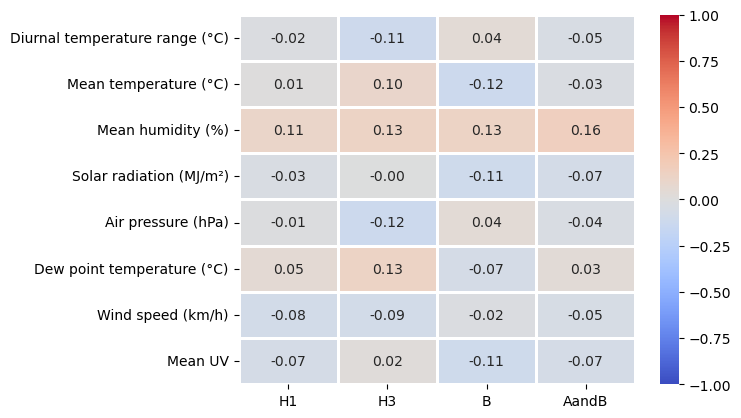

In [63]:
# correlation between meteorlogical factors and influenza detections
corr_df = df.drop(["Year", "Week", "From"], axis=1).corr(method="spearman")
corr_df = corr_df.loc[mete_col, flu_col]
display(corr_df)

sns.heatmap(corr_df, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=1)
plt.show()

We use scatterplot to identify the realtionship between the meterological data and influenza case counts for different types of influenza. 
The x-axis are the meterological data, while the y-axis represents different type of influenza
From the figure below, we can see that all relationships are non-linear and is ... 

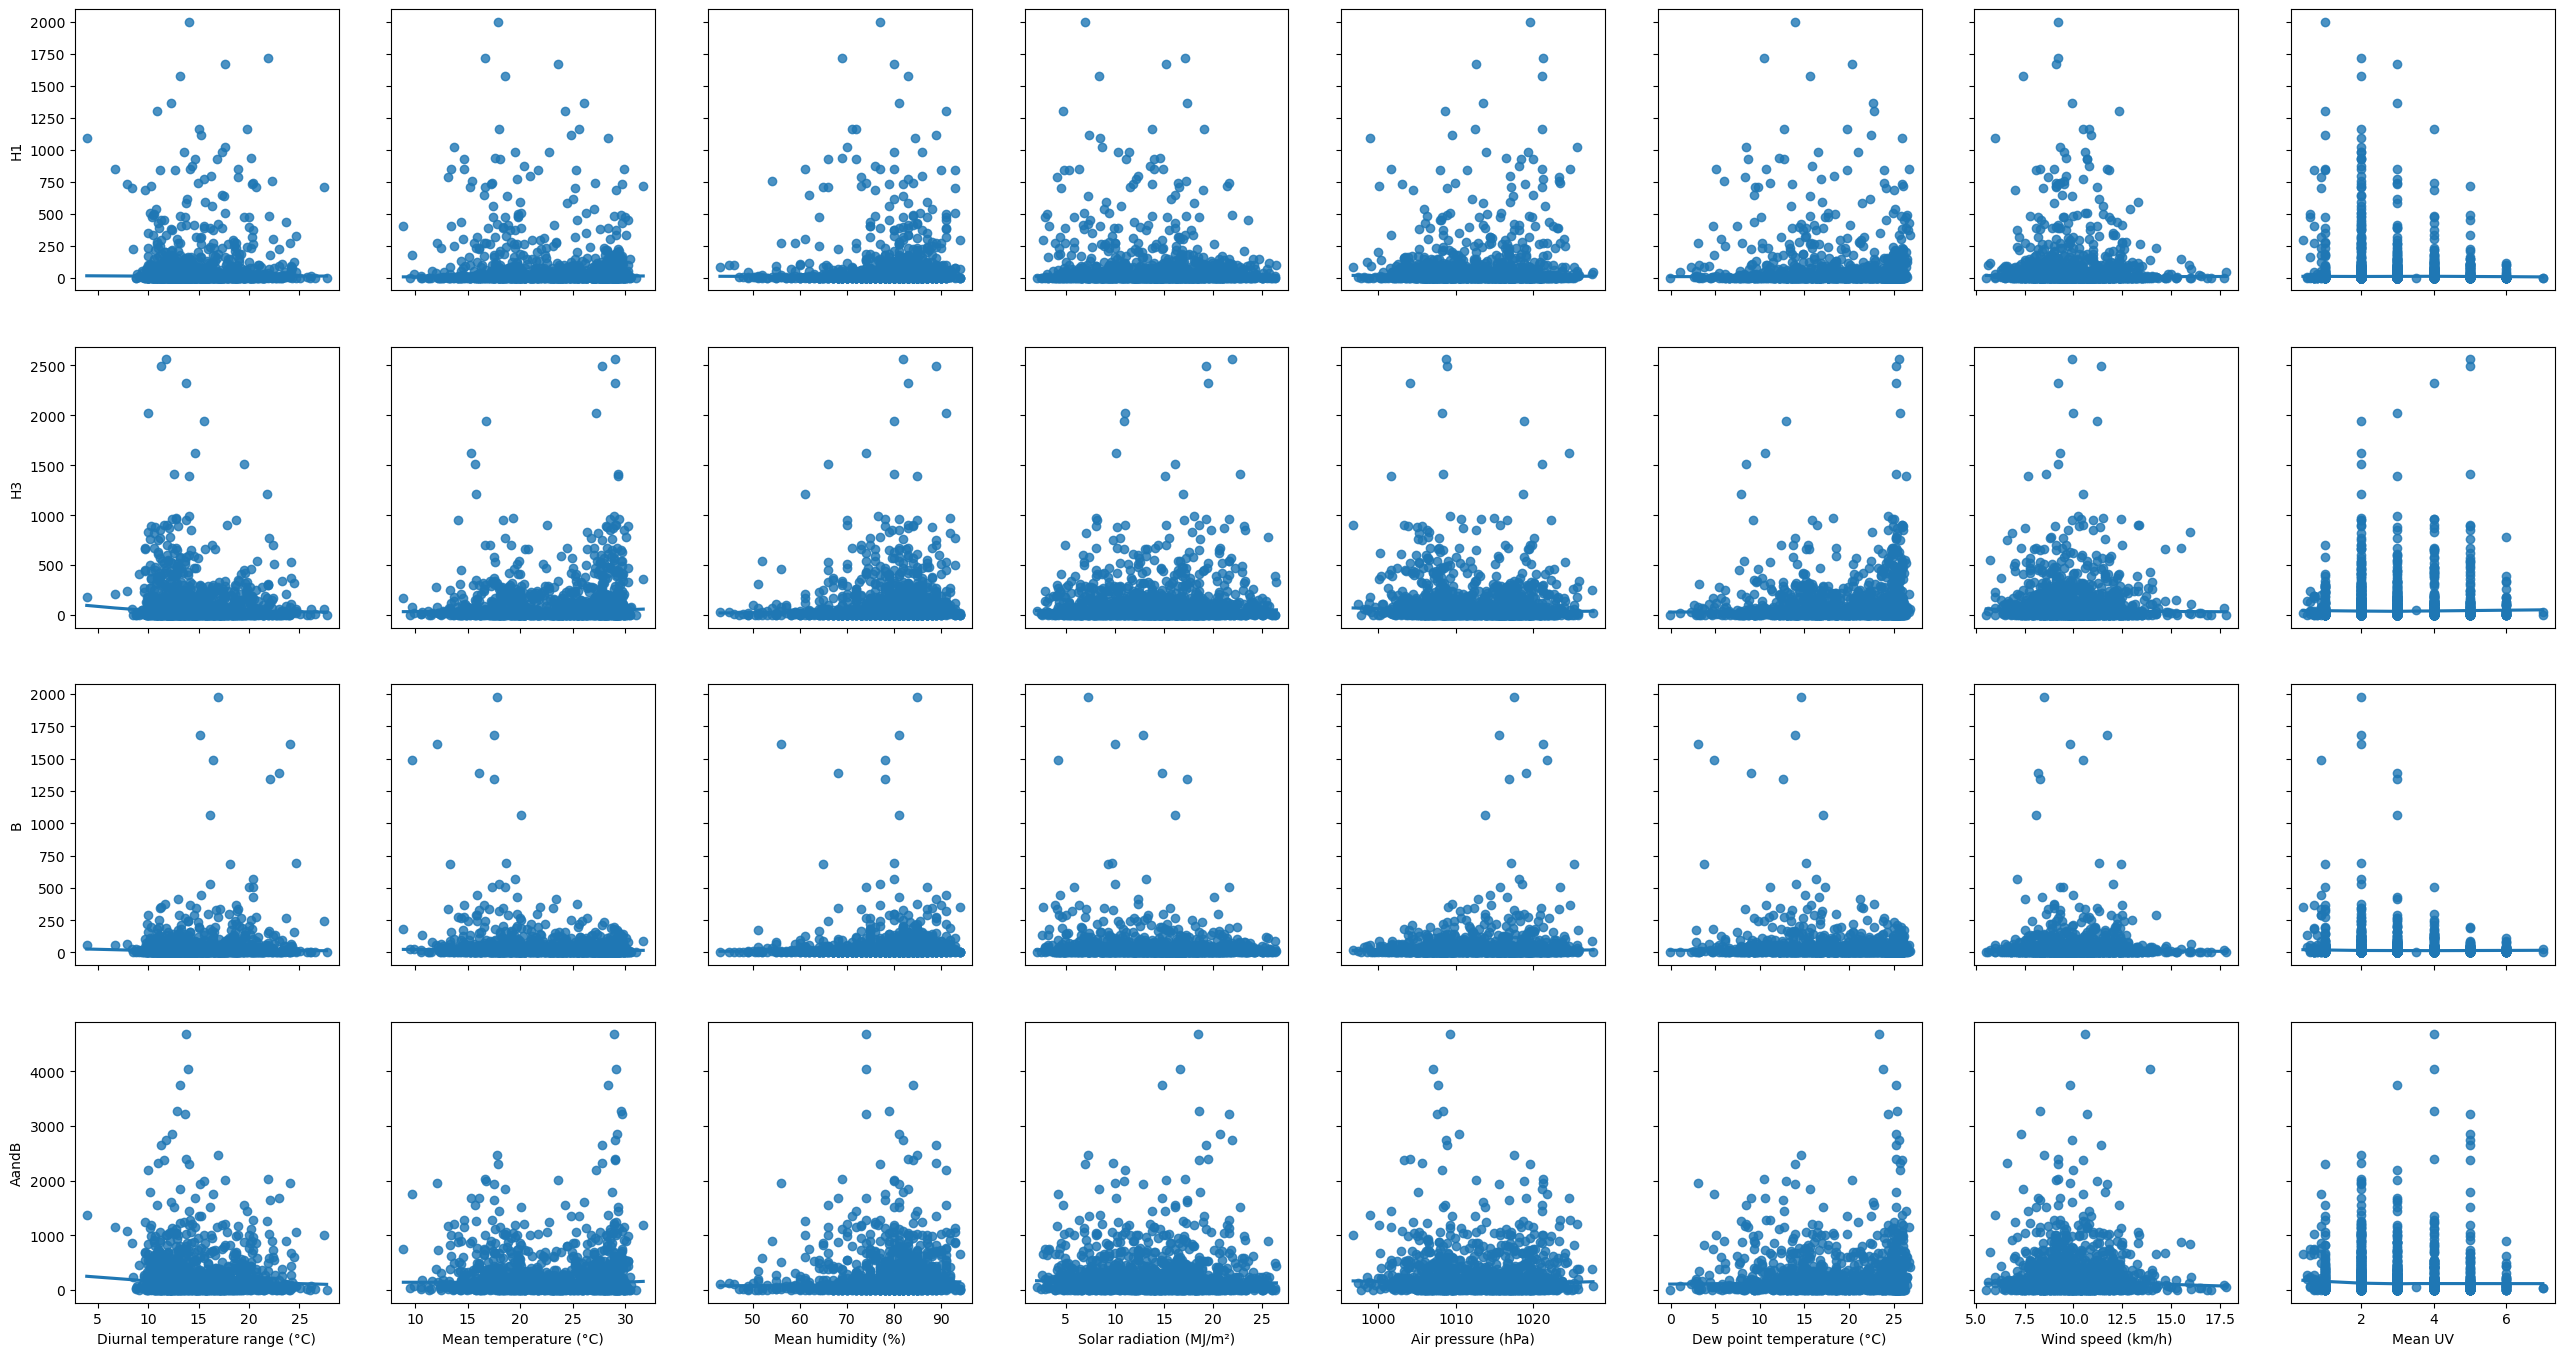

In [64]:
fig, axes = plt.subplots(4, 8, figsize=(6.4*5, 4.8*3.5))

for i, flu in enumerate(flu_col):
    for j, mete in enumerate(mete_col):
        sns.regplot(x=mete, y=flu, data=df, ax=axes[i, j], lowess=True)
        axes[i, j].set_xlabel(mete)
        axes[i, j].set_ylabel(flu)
        axes[i, j].label_outer()
        
plt.show()   


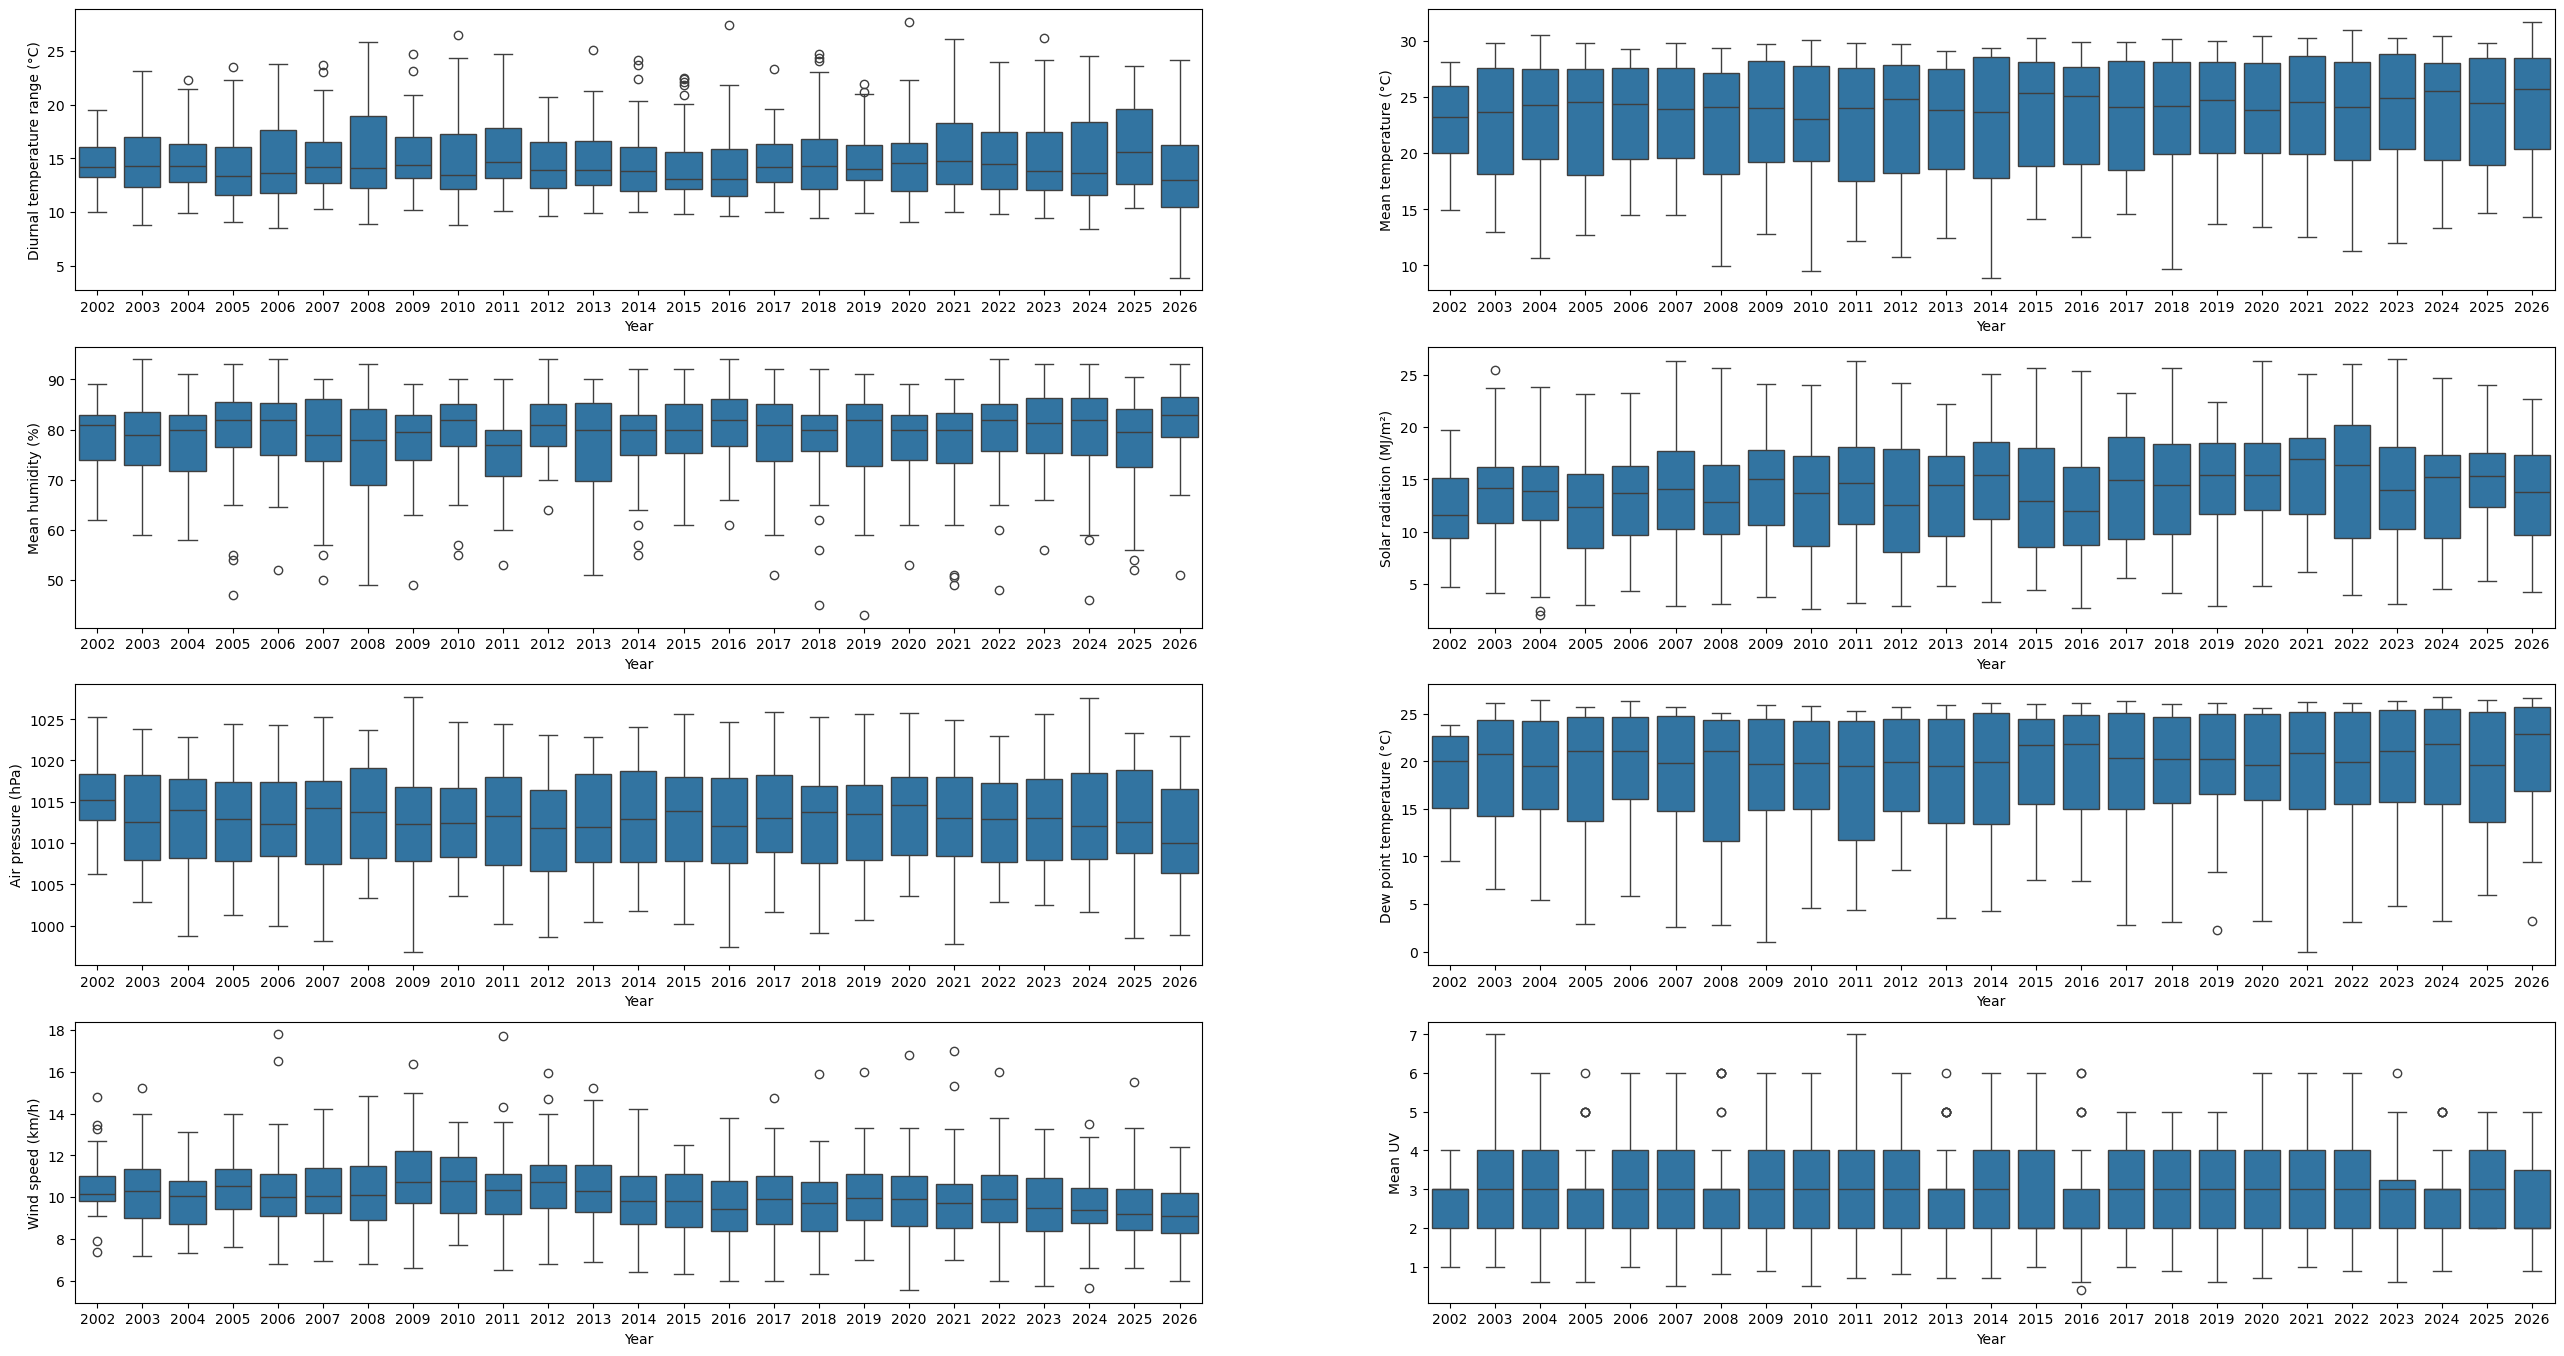

In [65]:
fig, axes = plt.subplots(4, 2, figsize=(6.4*5, 4.8*3.5))

for i, col in enumerate(mete_col):
    sns.boxplot(df[["Year", col]], x="Year", y=col, ax=axes[i//2, i%2])
    axes[i//2, i%2].set_xlabel("Year")
    axes[i//2, i%2].set_ylabel(col)

plt.show()

In [66]:
df_long = df.melt(
    id_vars=["From"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

fig = px.line(df_long, "From", "Influenza detections", color="Type",
              title="Number of detections based on timeline", 
              width=1500, height=600
             )

fig.show()

In [45]:
def lag_corr_cal(var_name, tar_name):
    corr_lst = []

    lags = [0, 1, 2, 3]

    for ax, lag in zip(axes.flatten(), lags):

        x_lagged = df[var_name].shift(lag)

        # Align observations and remove missing values
        temp = pd.concat(
            [df[tar_name], x_lagged],
            axis=1
        ).dropna()

        corr = temp[tar_name].corr(temp[var_name])
        corr_lst.append(corr)

    return corr_lst 

Lagged correlation between the variables and H1


,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
0,0.020635,-0.094926,0.036465,-0.087419,0.069088,-0.060578,-0.044543,-0.121010
1,0.024589,-0.111858,0.032886,-0.111789,0.087859,-0.077959,-0.044256,-0.141842
2,0.039966,-0.125510,0.022575,-0.119982,0.100439,-0.093849,-0.045816,-0.148828
3,0.062093,-0.132877,0.003920,-0.114807,0.113796,-0.106589,-0.046864,-0.150266


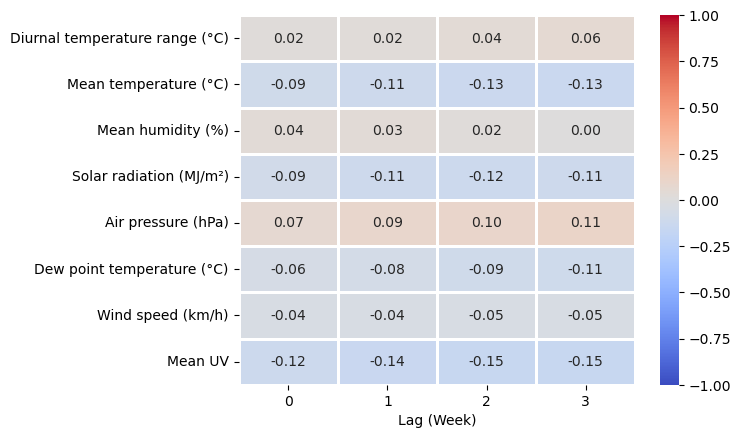

Lagged correlation between the variables and H3


,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
0,-0.101808,0.102643,0.087279,0.053517,-0.101364,0.110055,-0.028758,0.063906
1,-0.100660,0.092064,0.094053,0.044285,-0.092124,0.102744,-0.050271,0.058308
2,-0.092312,0.084217,0.092661,0.031048,-0.085691,0.096824,-0.060532,0.047173
3,-0.087312,0.080681,0.097396,0.010868,-0.089219,0.096164,-0.069279,0.032890


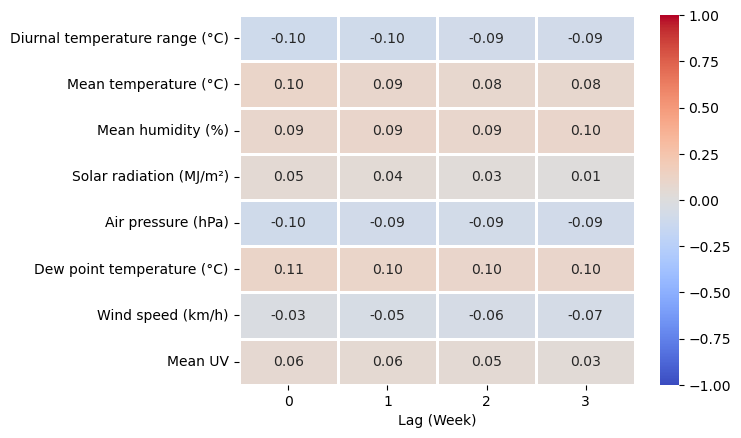

Lagged correlation between the variables and B


,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
0,0.131493,-0.189798,0.028537,-0.096752,0.106386,-0.149221,-0.023187,-0.105777
1,0.148171,-0.220580,0.000806,-0.105425,0.138302,-0.186306,-0.014803,-0.122639
2,0.148020,-0.246073,-0.021619,-0.130029,0.160471,-0.214748,0.010103,-0.148081
3,0.140302,-0.255595,-0.021764,-0.137604,0.175624,-0.222115,0.017025,-0.161666


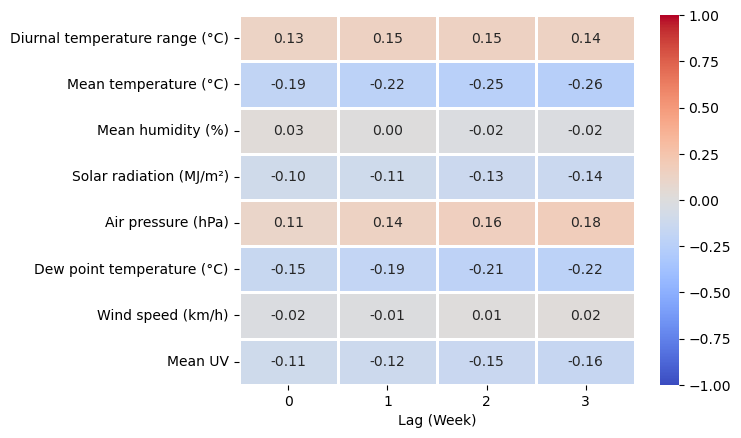

Lagged correlation between the variables and AandB


,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
0,-0.025187,-0.008071,0.067587,-0.012714,-0.023305,0.015571,-0.033643,-0.014738
1,-0.019544,-0.030242,0.065037,-0.031282,-0.005878,-0.005363,-0.043102,-0.032676
2,-0.007640,-0.047938,0.049812,-0.047008,0.006329,-0.024686,-0.039009,-0.044644
3,-0.002124,-0.056520,0.047484,-0.054987,0.013674,-0.032147,-0.055848,-0.052305


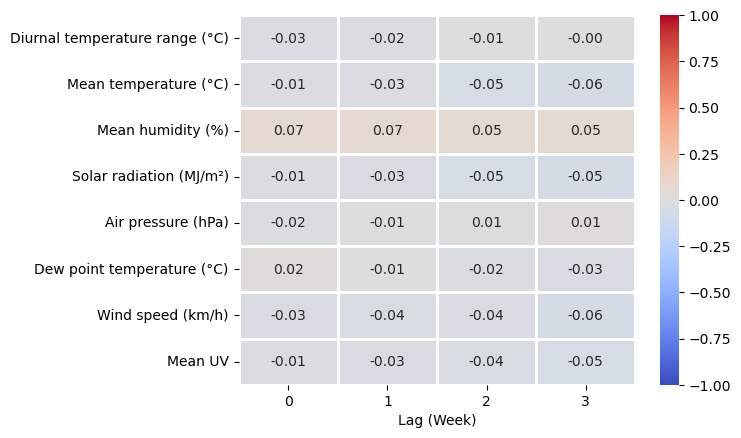

In [ ]:
for flu in flu_col:
    corr_lst = []
    for mete in mete_col:
        corr = lag_corr_cal(mete, flu)
        corr_lst.append(corr)

    print(f"Lagged correlation between the variables and type {flu} influenxa case counts")
    display(pd.DataFrame(corr_lst, index=mete_col).T)
    sns.heatmap(pd.DataFrame(corr_lst, index=mete_col), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=1)
    plt.xlabel("Lag (Week)")
    plt.show()

In [ ]:
# Test for stationarity with ADF test
for mete in mete_col:
    print(f"{mete} ADF p-value:", adfuller(df[mete].dropna(), result_object=False)[1])

for flu in flu_col:
    print(f"{flu} ADF p-value:", adfuller(df[flu].dropna(), result_object=False)[1])


Diurnal temperature range (°C) ADF p-value: 9.72706889039368e-24
Mean temperature (°C) ADF p-value: 2.1508674892395732e-24
Mean humidity (%) ADF p-value: 5.98549022678368e-18
Solar radiation (MJ/m²) ADF p-value: 5.64608784548384e-17
Air pressure (hPa) ADF p-value: 4.63618750842299e-28
Dew point temperature (°C) ADF p-value: 1.4552551550631437e-24
Wind speed (km/h) ADF p-value: 1.697348805767327e-26
Mean UV ADF p-value: 4.4678619714055217e-23
H1 ADF p-value: 1.3724247720784995e-12
H3 ADF p-value: 2.9996852009556233e-13
B ADF p-value: 3.746676484677444e-09
AandB ADF p-value: 2.6988637442982515e-11


In [79]:
# Test for cointegration 
for mete in mete_col:
    for flu in flu_col:
        score, pvalue, crit_values = coint(df[flu], df[mete])

        print(f"\n{mete} & {flu}:")
        print(f"Test Statistics: {score:.4f}")
        print(f"P-value: {pvalue:.4f}")
        print(f"Critical Value (1%, 5%, 10%): {crit_values}")


Diurnal temperature range (°C) & H1:
Test Statistics: -8.0683
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Diurnal temperature range (°C) & H3:
Test Statistics: -8.2723
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Diurnal temperature range (°C) & B:
Test Statistics: -inf
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Diurnal temperature range (°C) & AandB:
Test Statistics: -7.6230
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Mean temperature (°C) & H1:
Test Statistics: -7.4724
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Mean temperature (°C) & H3:
Test Statistics: -8.4436
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Mean temperature (°C) & B:
Test Statistics: -inf
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Me

C:\Users\yanss\AppData\Local\Temp\ipykernel_37996\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.

C:\Users\yanss\AppData\Local\Temp\ipykernel_37996\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.




Mean humidity (%) & H1:
Test Statistics: -8.1722
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Mean humidity (%) & H3:
Test Statistics: -7.2868
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Mean humidity (%) & B:
Test Statistics: -inf
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Mean humidity (%) & AandB:
Test Statistics: -7.6332
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Solar radiation (MJ/m²) & H1:
Test Statistics: -8.4870
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Solar radiation (MJ/m²) & H3:
Test Statistics: -8.2530
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Solar radiation (MJ/m²) & B:
Test Statistics: -inf
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Solar radiation (MJ/m²) & AandB:
Test Statistics

C:\Users\yanss\AppData\Local\Temp\ipykernel_37996\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.

C:\Users\yanss\AppData\Local\Temp\ipykernel_37996\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.

C:\Users\yanss\AppData\Local\Temp\ipykernel_37996\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.




Air pressure (hPa) & H3:
Test Statistics: -7.2917
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Air pressure (hPa) & B:
Test Statistics: -inf
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Air pressure (hPa) & AandB:
Test Statistics: -7.5861
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Dew point temperature (°C) & H1:
Test Statistics: -8.1433
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Dew point temperature (°C) & H3:
Test Statistics: -7.3382
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Dew point temperature (°C) & B:
Test Statistics: -inf
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Dew point temperature (°C) & AandB:
Test Statistics: -7.5879
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Wind speed (km/h) & H1:


C:\Users\yanss\AppData\Local\Temp\ipykernel_37996\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.

C:\Users\yanss\AppData\Local\Temp\ipykernel_37996\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.

C:\Users\yanss\AppData\Local\Temp\ipykernel_37996\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.




Wind speed (km/h) & AandB:
Test Statistics: -7.5859
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Mean UV & H1:
Test Statistics: -8.5834
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Mean UV & H3:
Test Statistics: -8.2624
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Mean UV & B:
Test Statistics: -inf
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Mean UV & AandB:
Test Statistics: -7.6108
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]


In [82]:
X = df[mete_col]

vif = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

with pd.option_context("display.max_rows", 173):
    display(vif.sort_values("VIF", ascending=False))

,Variable,VIF
5,Dew point temperature (°C),134.747528
1,Mean temperature (°C),95.874813
2,Mean humidity (%),17.686105
3,Solar radiation (MJ/m²),7.610842
7,Mean UV,7.298033
4,Air pressure (hPa),5.342290
0,Diurnal temperature range (°C),2.442852
6,Wind speed (km/h),1.141350
